# Healthcare Machine Learning Capstone: Diabetes Prediction
## End-to-end classification project using the Pima Indians Diabetes Dataset

**Goal:** Predict the binary target `Outcome` (0 = no diabetes, 1 = diabetes) from diagnostic measurements.

**Dataset:** [Pima Indians Diabetes Database – Kaggle](https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database)



## 1. Business / problem understanding
Healthcare providers may want to identify patients who could benefit from further clinical assessment. This project demonstrates a binary classification workflow, comparing multiple algorithms and emphasizing recall, precision, F1-score, ROC-AUC and the confusion matrix—not accuracy alone.

### Dataset features
- `Pregnancies`: number of pregnancies
- `Glucose`: plasma glucose concentration
- `BloodPressure`: diastolic blood pressure
- `SkinThickness`: triceps skin-fold thickness
- `Insulin`: 2-hour serum insulin
- `BMI`: body mass index
- `DiabetesPedigreeFunction`: diabetes pedigree score
- `Age`: age in years
- `Outcome`: target (0 / 1)

## 2. Download and load the Kaggle dataset

1. Open the Kaggle dataset link above.
2. Select **Download** and extract `diabetes.csv`.
3. Place `diabetes.csv` in the same folder as this notebook.

For Google Colab, upload `diabetes.csv` using the Files panel or run the optional upload cell.

In [1]:
# Optional: use this cell in Google Colab to upload diabetes.csv
# from google.colab import files
# uploaded = files.upload()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")


dataset = pd.read_csv(r'C:\Users\LakshmanAIMLHYD\Desktop\AI&ML(8-9)\4.ML\diabetes (1).csv')

print("Dataset loaded successfully")

Dataset loaded successfully


## 3. Data understanding

In [2]:
dataset.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
dataset.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [4]:
dataset.shape

(768, 9)

In [5]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [6]:
dataset.dtypes

Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

In [7]:
dataset.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [8]:
dataset.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='str')

In [9]:
print("Duplicate rows:", dataset.duplicated().sum())
print("\\nMissing values:")
display(dataset.isnull().sum())

Duplicate rows: 0
\nMissing values:


Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

## 4. Data cleaning

In this dataset, zero values in `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` and `BMI` are not physiologically plausible measurements for this use case. Treat these zeros as missing values. Do not replace zero in `Pregnancies` or `Outcome`.

We will impute missing values with the **median calculated from the training data only**, inside a scikit-learn pipeline. This prevents data leakage.

In [10]:
dataset = dataset.copy()
zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
dataset[zero_as_missing] = dataset[zero_as_missing].replace(0, np.nan)

print("Missing values after replacing invalid zeros:")
display(dataset.isnull().sum())

Missing values after replacing invalid zeros:


Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

In [11]:
# Check target distribution and remove rows with a missing target, if any
dataset = dataset.dropna(subset=["Outcome"])
dataset["Outcome"] = dataset["Outcome"].astype(int)

print(dataset["Outcome"].value_counts())
print(dataset["Outcome"].value_counts(normalize=True).round(3))

Outcome
0    500
1    268
Name: count, dtype: int64
Outcome
0    0.651
1    0.349
Name: proportion, dtype: float64


## 5. Exploratory Data Analysis (EDA)

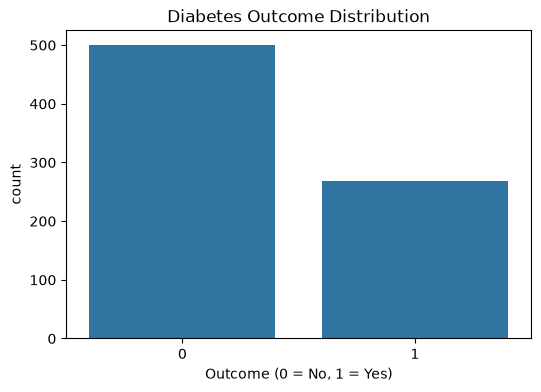

In [12]:
plt.figure(figsize=(6, 4))
sns.countplot(data=dataset, x="Outcome")
plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome (0 = No, 1 = Yes)")
plt.show()

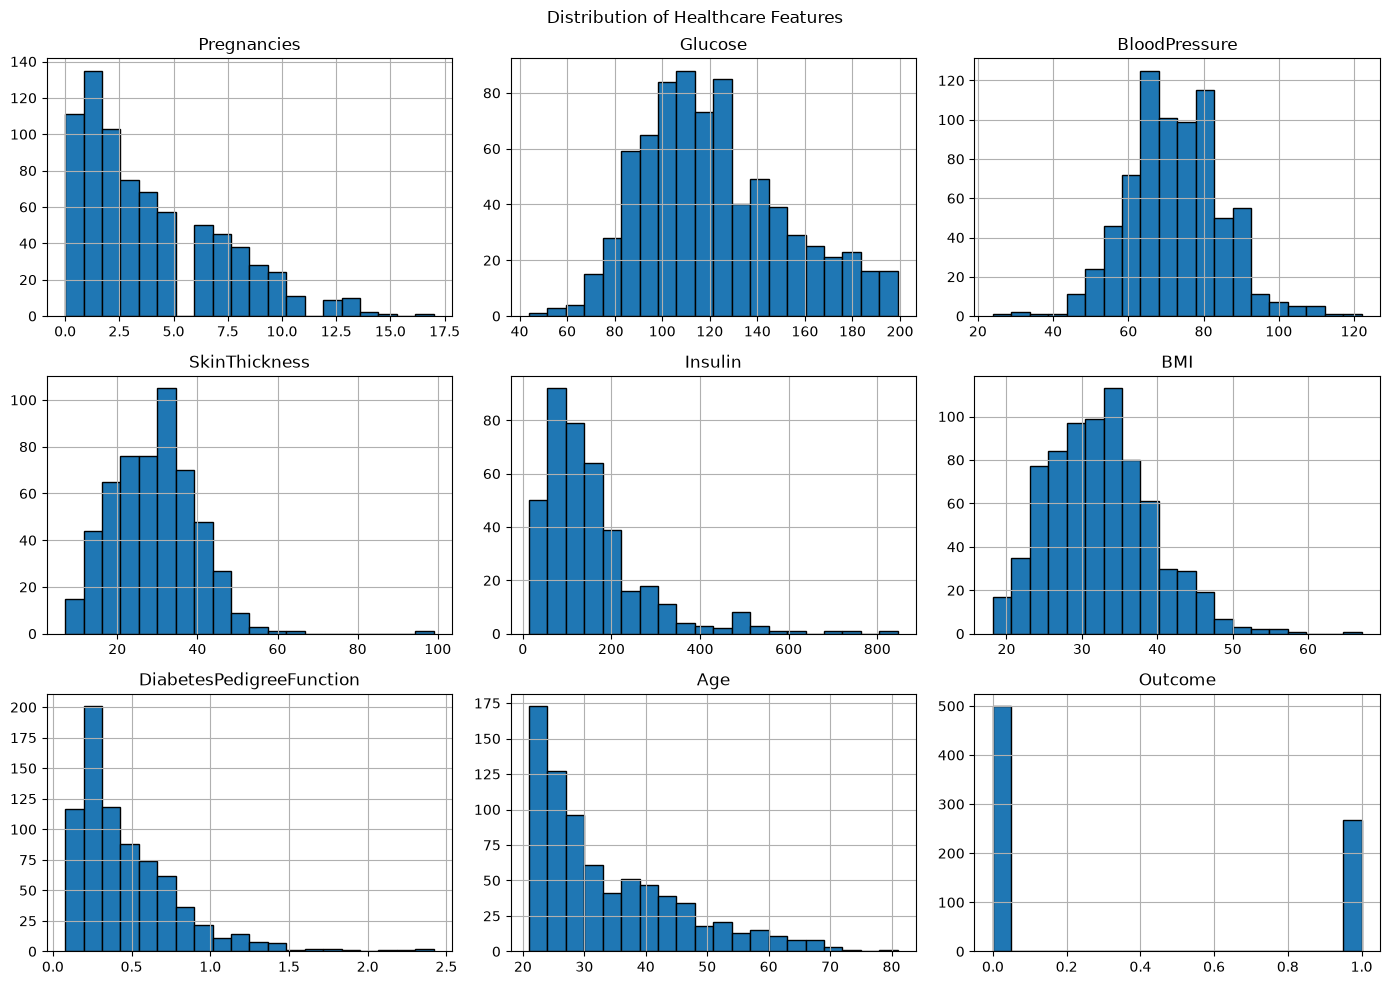

In [13]:
dataset.hist(figsize=(14, 10), bins=20, edgecolor="black")
plt.suptitle("Distribution of Healthcare Features")
plt.tight_layout()
plt.show()

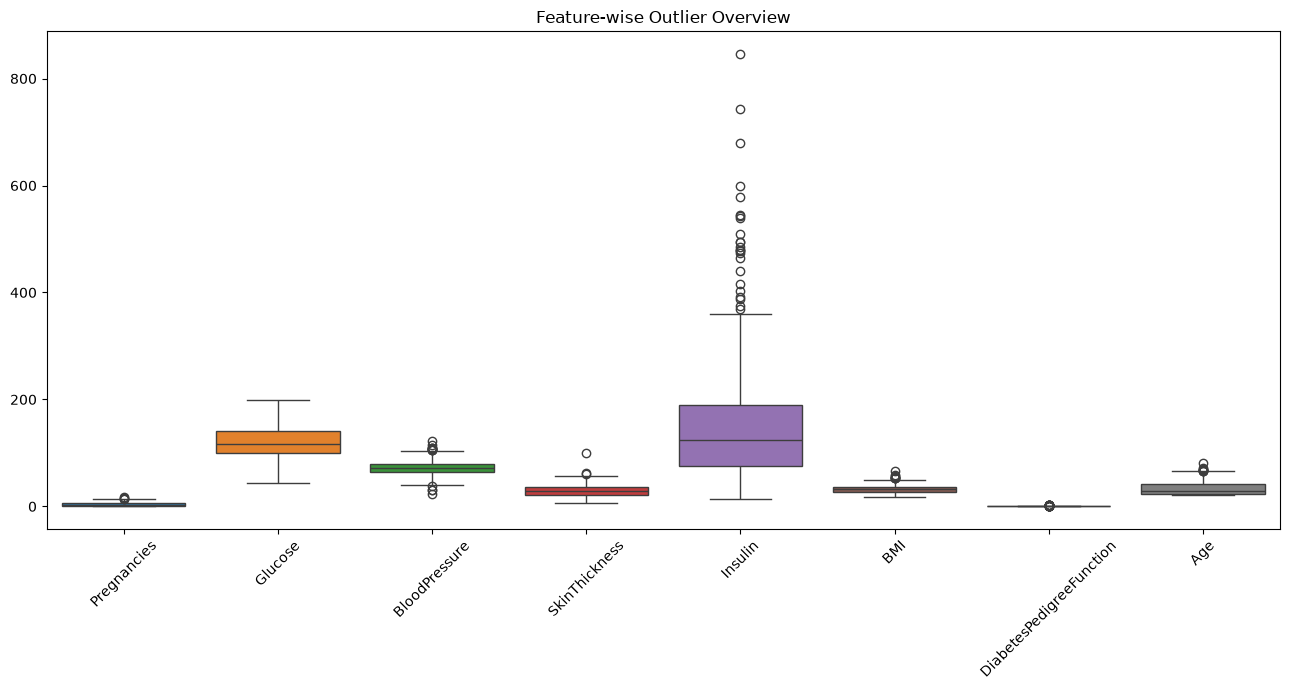

In [14]:
plt.figure(figsize=(13, 7))
sns.boxplot(data=dataset.drop(columns="Outcome"))
plt.xticks(rotation=45)
plt.title("Feature-wise Outlier Overview")
plt.tight_layout()
plt.show()

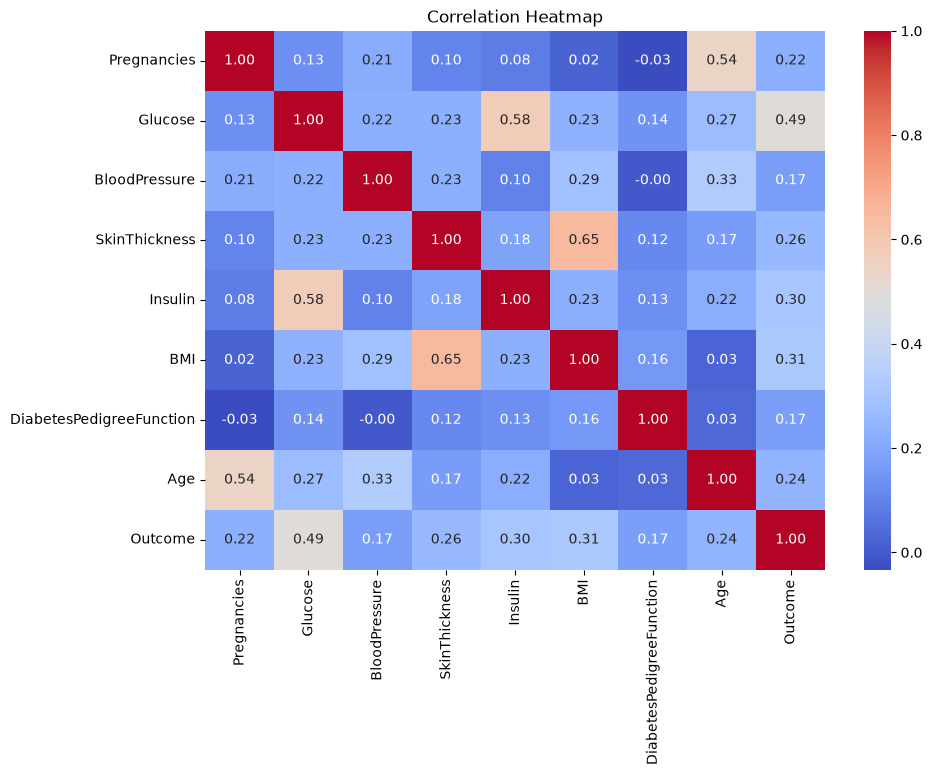

In [15]:
plt.figure(figsize=(10, 7))
sns.heatmap(dataset.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

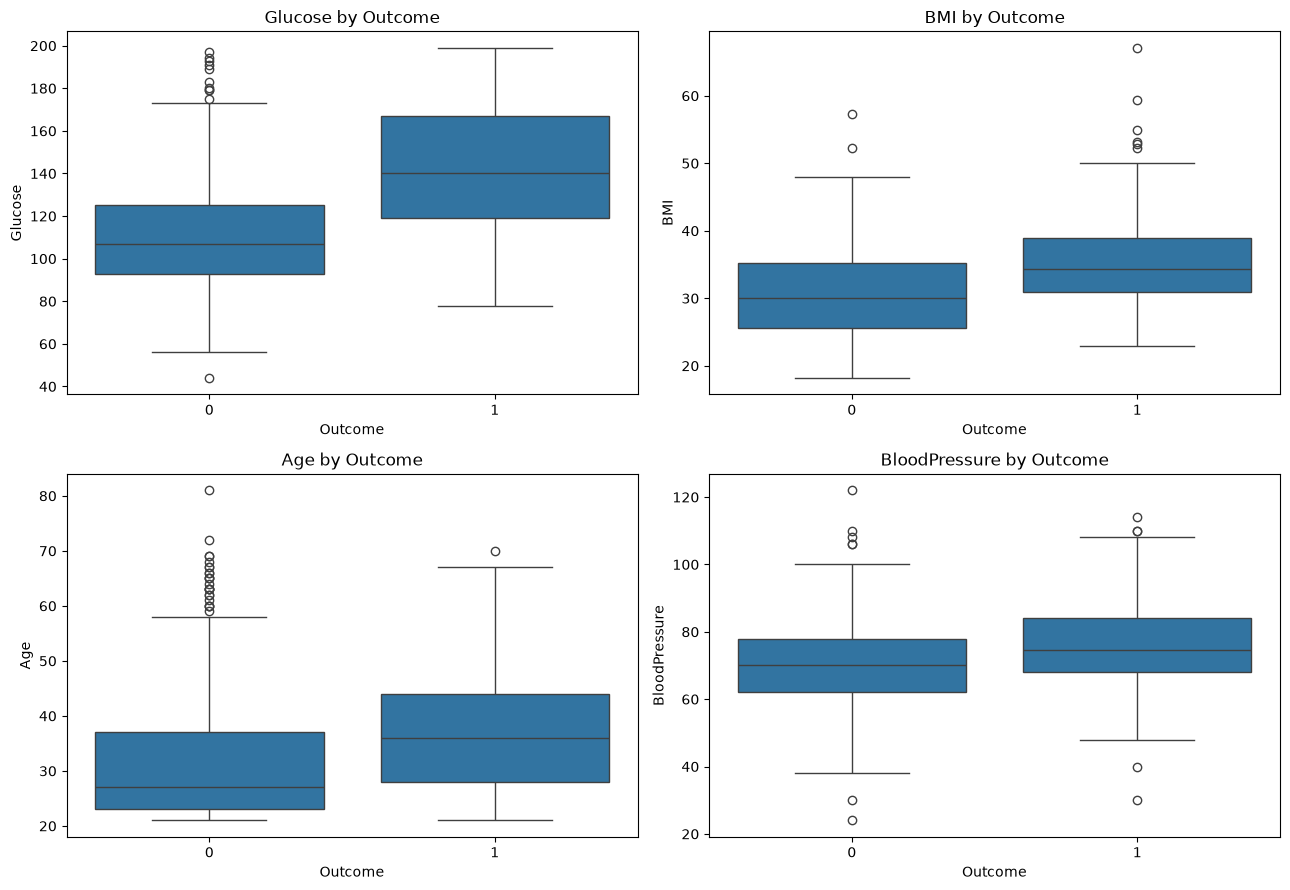

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, feature in zip(axes.flat, ["Glucose", "BMI", "Age", "BloodPressure"]):
    sns.boxplot(data=dataset, x="Outcome", y=feature, ax=ax)
    ax.set_title(f"{feature} by Outcome")
plt.tight_layout()
plt.show()

## 6. Feature / target split and train-test split

We use a stratified split so the proportion of both target classes is maintained in train and test sets. The test set is held out for final evaluation.

In [17]:
from sklearn.model_selection import train_test_split

X = dataset.drop(columns="Outcome")
y = dataset["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=17, stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("\\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

X_train: (614, 8)
X_test : (154, 8)
\nTraining target distribution:
Outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64


## 7. Preprocessing and evaluation setup

Median imputation and standard scaling are used for Logistic Regression. Tree-based algorithms use median imputation without scaling. All preprocessing is fitted within each model pipeline.

In [18]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay
)
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=17)

def evaluate_model(name, model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else None

    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, y_prob) if y_prob is not None else np.nan
    }

    print(f"===== {name} =====")
    print(classification_report(y_test, y_pred, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
    plt.title(f"{name} - Confusion Matrix")
    plt.show()
    return results

## 8. Logistic Regression

Logistic Regression is a classification algorithm that estimates the probability of the positive class. Standardization is important because the input features use different scales.

===== Logistic Regression =====
              precision    recall  f1-score   support

           0       0.90      0.75      0.82       100
           1       0.65      0.85      0.74        54

    accuracy                           0.79       154
   macro avg       0.78      0.80      0.78       154
weighted avg       0.81      0.79      0.79       154



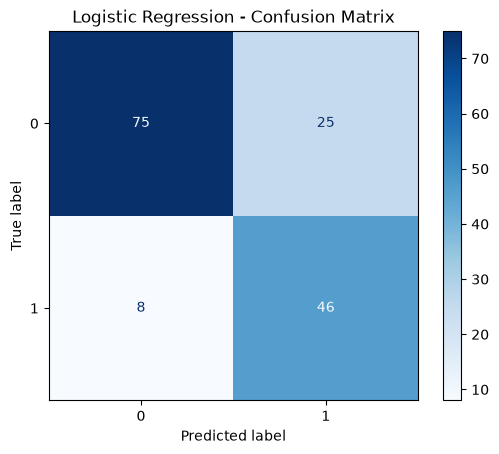

In [19]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=17))
])

results = []
results.append(evaluate_model(
    "Logistic Regression", logistic_model,
    X_train, y_train, X_test, y_test
))

## 9. Regularization: L1 (Lasso-style) and L2 (Ridge-style)

For Logistic Regression, L1 regularization can shrink some coefficients to zero (feature selection), while L2 regularization shrinks coefficients smoothly. These are the classification equivalents of Lasso and Ridge regression.

Best L1 parameters: {'classifier__C': 0.1}
===== L1 Logistic Regression =====
              precision    recall  f1-score   support

           0       0.91      0.71      0.80       100
           1       0.62      0.87      0.72        54

    accuracy                           0.77       154
   macro avg       0.76      0.79      0.76       154
weighted avg       0.81      0.77      0.77       154



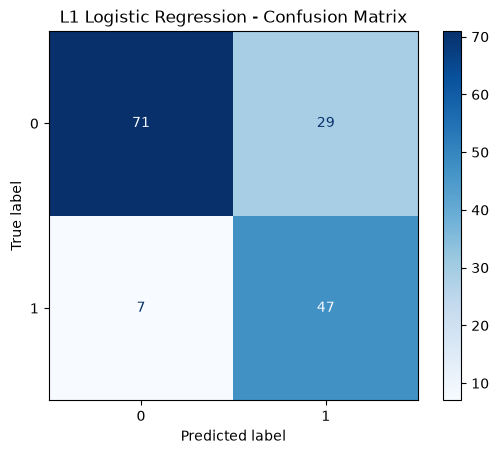

In [20]:
# L1-regularized Logistic Regression (Lasso-style)
l1_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        penalty="l1", solver="liblinear", class_weight="balanced",
        max_iter=2000, random_state=17
    ))
])

l1_grid = GridSearchCV(
    l1_pipeline,
    {"classifier__C": [0.01, 0.1, 1, 10, 100]},
    scoring="roc_auc", cv=cv, n_jobs=-1
)
l1_grid.fit(X_train, y_train)
print("Best L1 parameters:", l1_grid.best_params_)
results.append(evaluate_model(
    "L1 Logistic Regression", l1_grid.best_estimator_,
    X_train, y_train, X_test, y_test
))

Best L2 parameters: {'classifier__C': 0.1}
===== L2 Logistic Regression =====
              precision    recall  f1-score   support

           0       0.89      0.74      0.81       100
           1       0.63      0.83      0.72        54

    accuracy                           0.77       154
   macro avg       0.76      0.79      0.76       154
weighted avg       0.80      0.77      0.78       154



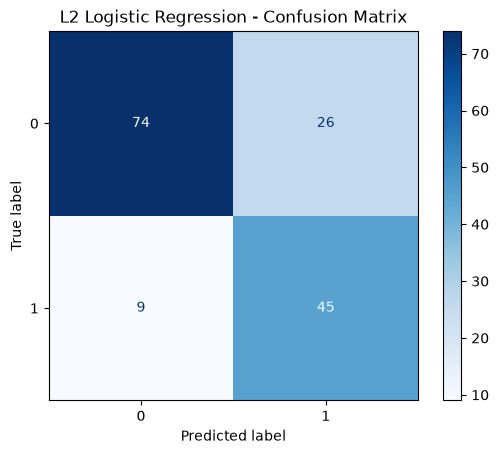

In [21]:
# L2-regularized Logistic Regression (Ridge-style)
l2_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        penalty="l2", solver="lbfgs", class_weight="balanced",
        max_iter=2000, random_state=17
    ))
])

l2_grid = GridSearchCV(
    l2_pipeline,
    {"classifier__C": [0.01, 0.1, 1, 10, 100]},
    scoring="roc_auc", cv=cv, n_jobs=-1
)
l2_grid.fit(X_train, y_train)
print("Best L2 parameters:", l2_grid.best_params_)
results.append(evaluate_model(
    "L2 Logistic Regression", l2_grid.best_estimator_,
    X_train, y_train, X_test, y_test
))

## 10. Gaussian Naive Bayes Classifier
Gaussian Naive Bayes is a probabilistic baseline. It assumes conditional independence between features and Gaussian feature distributions.

===== Gaussian Naive Bayes =====
              precision    recall  f1-score   support

           0       0.83      0.81      0.82       100
           1       0.66      0.69      0.67        54

    accuracy                           0.77       154
   macro avg       0.74      0.75      0.75       154
weighted avg       0.77      0.77      0.77       154



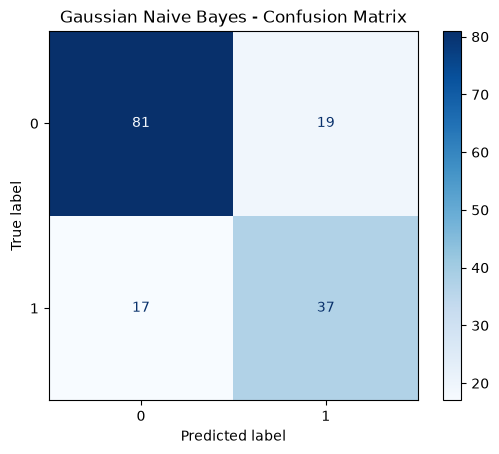

In [22]:
from sklearn.naive_bayes import GaussianNB

nb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", GaussianNB())
])

results.append(evaluate_model(
    "Gaussian Naive Bayes", nb_pipeline,
    X_train, y_train, X_test, y_test
))


## 11. K-Nearest Neighbors (KNN) Classifier
KNN predicts a patient's class using the majority class among nearby training examples. Scaling is important because KNN uses distance.

Best KNN parameters: {'classifier__n_neighbors': 15, 'classifier__p': 1, 'classifier__weights': 'uniform'}
===== KNN Tuned =====
              precision    recall  f1-score   support

           0       0.78      0.84      0.81       100
           1       0.65      0.56      0.60        54

    accuracy                           0.74       154
   macro avg       0.71      0.70      0.70       154
weighted avg       0.73      0.74      0.73       154



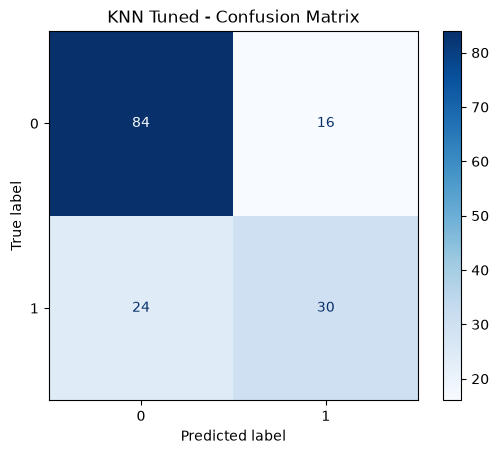

In [23]:
from sklearn.neighbors import KNeighborsClassifier

knn_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

knn_params = {
    "classifier__n_neighbors": [3, 5, 7, 9, 11, 15],
    "classifier__weights": ["uniform", "distance"],
    "classifier__p": [1, 2]
}
knn_grid = GridSearchCV(
    knn_pipeline, knn_params, scoring="roc_auc",
    cv=cv, n_jobs=-1
)
knn_grid.fit(X_train, y_train)
print("Best KNN parameters:", knn_grid.best_params_)
results.append(evaluate_model(
    "KNN Tuned", knn_grid.best_estimator_,
    X_train, y_train, X_test, y_test
))


## 12. Decision Tree Classifier
A Decision Tree learns rule-based splits. It is interpretable, but limiting tree depth and leaf size helps reduce overfitting.

Best Decision Tree parameters: {'classifier__criterion': 'gini', 'classifier__max_depth': 3, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2}
===== Decision Tree Tuned =====
              precision    recall  f1-score   support

           0       0.96      0.65      0.77       100
           1       0.59      0.94      0.73        54

    accuracy                           0.75       154
   macro avg       0.77      0.80      0.75       154
weighted avg       0.83      0.75      0.76       154



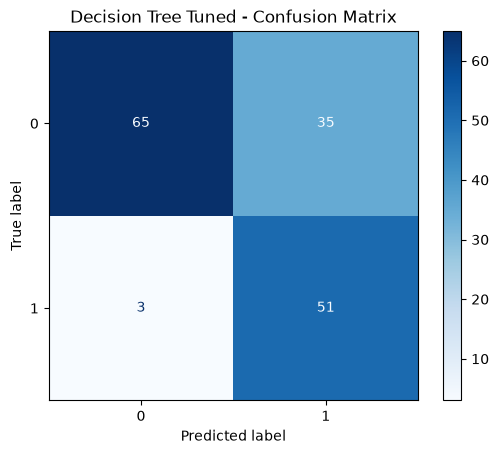

In [24]:
from sklearn.tree import DecisionTreeClassifier

dt_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", DecisionTreeClassifier(
        class_weight="balanced", random_state=17
    ))
])

dt_params = {
    "classifier__max_depth": [2, 3, 4, 5, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__criterion": ["gini", "entropy"]
}
dt_grid = GridSearchCV(
    dt_pipeline, dt_params, scoring="roc_auc",
    cv=5, n_jobs=-1
)
dt_grid.fit(X_train, y_train)
print("Best Decision Tree parameters:", dt_grid.best_params_)
results.append(evaluate_model(
    "Decision Tree Tuned", dt_grid.best_estimator_,
    X_train, y_train, X_test, y_test
))


## 13. Random Forest Classifier

Best Random Forest parameters: {'classifier__max_depth': 5, 'classifier__min_samples_leaf': 4, 'classifier__min_samples_split': 2}
===== Random Forest =====
              precision    recall  f1-score   support

           0       0.95      0.74      0.83       100
           1       0.66      0.93      0.77        54

    accuracy                           0.81       154
   macro avg       0.80      0.83      0.80       154
weighted avg       0.85      0.81      0.81       154



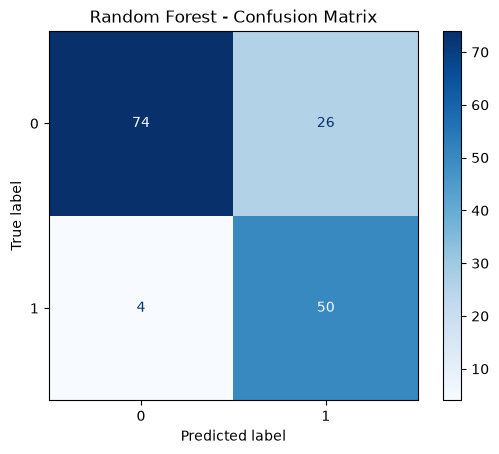

In [26]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=300, class_weight="balanced",
        random_state=17, n_jobs=-1
    ))
])

rf_params = {
    "classifier__max_depth": [3, 5, 8, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4]
}
rf_grid = GridSearchCV(rf_pipeline, rf_params, scoring="roc_auc", cv=5, n_jobs=-1)
rf_grid.fit(X_train, y_train)
print("Best Random Forest parameters:", rf_grid.best_params_)
results.append(evaluate_model(
    "Random Forest", rf_grid.best_estimator_,
    X_train, y_train, X_test, y_test
))

## 14. Gradient Boosting Classifier

Best Gradient Boosting parameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 1, 'classifier__n_estimators': 100, 'classifier__subsample': 0.8}
===== Gradient Boosting =====
              precision    recall  f1-score   support

           0       0.83      0.86      0.85       100
           1       0.73      0.69      0.70        54

    accuracy                           0.80       154
   macro avg       0.78      0.77      0.78       154
weighted avg       0.80      0.80      0.80       154



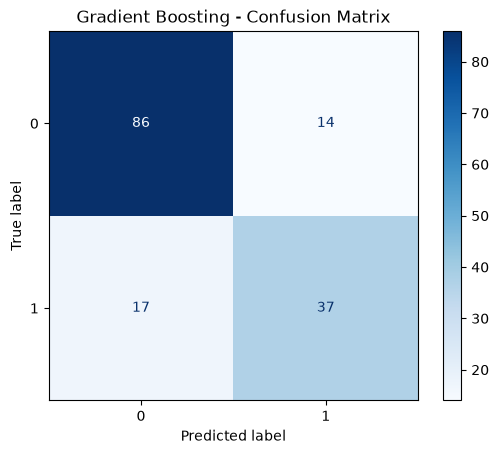

In [27]:
from sklearn.ensemble import GradientBoostingClassifier

gb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", GradientBoostingClassifier(random_state=17))
])

gb_params = {
    "classifier__n_estimators": [100, 200],
    "classifier__learning_rate": [0.03, 0.1],
    "classifier__max_depth": [1, 2, 3],
    "classifier__subsample": [0.8, 1.0]
}
gb_grid = GridSearchCV(gb_pipeline, gb_params, scoring="roc_auc", cv=10, n_jobs=-1)
gb_grid.fit(X_train, y_train)
print("Best Gradient Boosting parameters:", gb_grid.best_params_)
results.append(evaluate_model(
    "Gradient Boosting", gb_grid.best_estimator_,
    X_train, y_train, X_test, y_test
))

## 15. Default XGBoost Classifier

In [28]:
!pip install xgboost

  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)


===== XGBoost Default =====
              precision    recall  f1-score   support

           0       0.87      0.84      0.85       100
           1       0.72      0.76      0.74        54

    accuracy                           0.81       154
   macro avg       0.79      0.80      0.80       154
weighted avg       0.81      0.81      0.81       154



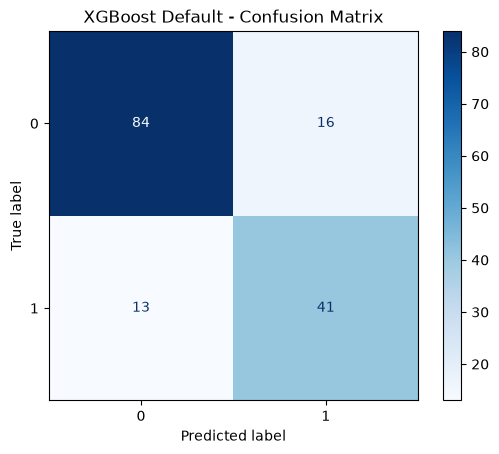

In [29]:
# If needed, install once: %pip install xgboost
from xgboost import XGBClassifier

xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", XGBClassifier(
        n_estimators=250, max_depth=3, learning_rate=0.05,
        subsample=0.9, colsample_bytree=0.9,
        objective="binary:logistic", eval_metric="logloss",
        random_state=17, n_jobs=-1
    ))
])

results.append(evaluate_model(
    "XGBoost Default", xgb_pipeline,
    X_train, y_train, X_test, y_test
))

## 13. Hyperparameter tuning on XGBoost

Fitting 15 folds for each of 48 candidates, totalling 720 fits
Best XGBoost parameters: {'classifier__colsample_bytree': 1.0, 'classifier__learning_rate': 0.03, 'classifier__max_depth': 2, 'classifier__n_estimators': 100, 'classifier__subsample': 0.8}
Best CV ROC-AUC: 0.825776692443359
===== XGBoost Tuned =====
              precision    recall  f1-score   support

           0       0.85      0.90      0.87       100
           1       0.79      0.70      0.75        54

    accuracy                           0.83       154
   macro avg       0.82      0.80      0.81       154
weighted avg       0.83      0.83      0.83       154



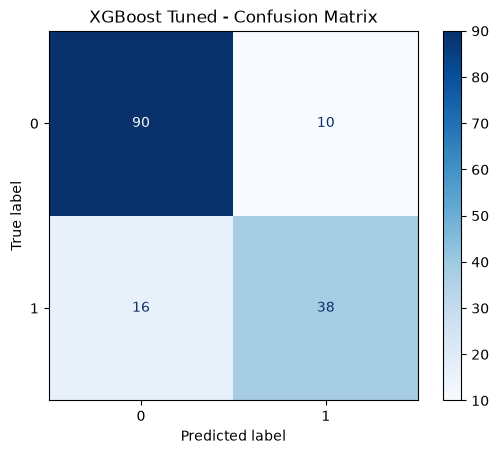

In [30]:
xgb_tune_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", XGBClassifier(
        objective="binary:logistic", eval_metric="logloss",
        random_state=17, n_jobs=-1
    ))
])

xgb_params = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [2, 3, 4],
    "classifier__learning_rate": [0.03, 0.1],
    "classifier__subsample": [0.8, 1.0],
    "classifier__colsample_bytree": [0.8, 1.0]
}
xgb_grid = GridSearchCV(
    xgb_tune_pipeline, xgb_params, scoring="roc_auc",
    cv=15, n_jobs=-1, verbose=1
)
xgb_grid.fit(X_train, y_train)
print("Best XGBoost parameters:", xgb_grid.best_params_)
print("Best CV ROC-AUC:", xgb_grid.best_score_)
results.append(evaluate_model(
    "XGBoost Tuned", xgb_grid.best_estimator_,
    X_train, y_train, X_test, y_test
))

## 17. CatBoost Classifier (optional)

In [31]:
! pip install catboost

  Using cached catboost-1.2.10-cp312-cp312-win_amd64.whl.metadata (1.5 kB)
  Using cached graphviz-0.21-py3-none-any.whl.metadata (12 kB)
  Using cached plotly-7.2.0-py3-none-any.whl.metadata (9.2 kB)
Using cached catboost-1.2.10-cp312-cp312-win_amd64.whl (100.2 MB)
Using cached graphviz-0.21-py3-none-any.whl (47 kB)
Using cached plotly-7.2.0-py3-none-any.whl (9.7 MB)

   ---------------------------------------- 0/3 [plotly]
   ---------------------------------------- 0/3 [plotly]
   ---------------------------------------- 0/3 [plotly]
   ---------------------------------------- 0/3 [plotly]
   ---------------------------------------- 0/3 [plotly]
   ---------------------------------------- 0/3 [plotly]
   ---------------------------------------- 0/3 [plotly]
   ---------------------------------------- 0/3 [plotly]
   ---------------------------------------- 0/3 [plotly]
   ---------------------------------------- 0/3 [plotly]
   ---------------------------------------- 0/3 [plotly]
 

===== CatBoost =====
              precision    recall  f1-score   support

           0       0.91      0.78      0.84       100
           1       0.68      0.85      0.75        54

    accuracy                           0.81       154
   macro avg       0.79      0.82      0.80       154
weighted avg       0.83      0.81      0.81       154



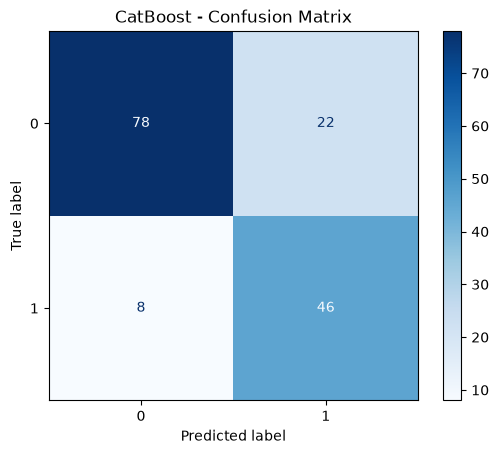

In [32]:
# If needed, install once: %pip install catboost
from catboost import CatBoostClassifier

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", CatBoostClassifier(
        iterations=400, depth=4, learning_rate=0.03,
        loss_function="Logloss", verbose=False,
        random_seed=17, auto_class_weights="Balanced"
    ))
])

results.append(evaluate_model(
    "CatBoost", cat_pipeline,
    X_train, y_train, X_test, y_test
))

## 15. Compare all models

The primary comparison metric is ROC-AUC, but in a healthcare context inspect recall and precision together. A higher recall means fewer positive cases are missed at the selected threshold, while precision describes how many predicted positives are actually positive in this dataset.

In [33]:
results_df = pd.DataFrame(results).sort_values("ROC_AUC", ascending=False)
display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
9,XGBoost Tuned,0.831,0.792,0.704,0.745,0.901
7,Gradient Boosting,0.799,0.725,0.685,0.705,0.892
6,Random Forest,0.805,0.658,0.926,0.769,0.885
5,Decision Tree Tuned,0.753,0.593,0.944,0.729,0.876
10,CatBoost,0.805,0.676,0.852,0.754,0.871
1,L1 Logistic Regression,0.766,0.618,0.870,0.723,0.870
2,L2 Logistic Regression,0.773,0.634,0.833,0.720,0.870
0,Logistic Regression,0.786,0.648,0.852,0.736,0.869
8,XGBoost Default,0.812,0.719,0.759,0.739,0.867
4,KNN Tuned,0.740,0.652,0.556,0.600,0.850


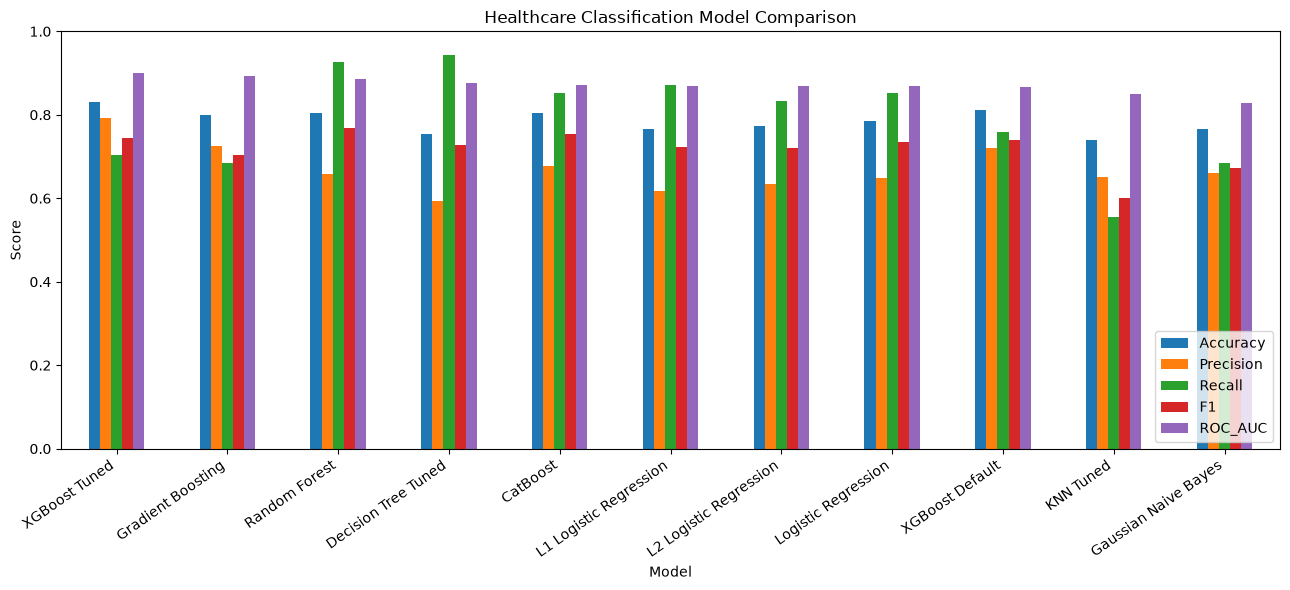

In [34]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]
results_df.set_index("Model")[metrics_to_plot].plot(
    kind="bar", figsize=(13, 6), ylim=(0, 1)
)
plt.title("Healthcare Classification Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=35, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 16. ROC curve comparison

This plot compares the ability of the fitted models to separate the two classes across thresholds. It does not identify a clinically appropriate threshold.

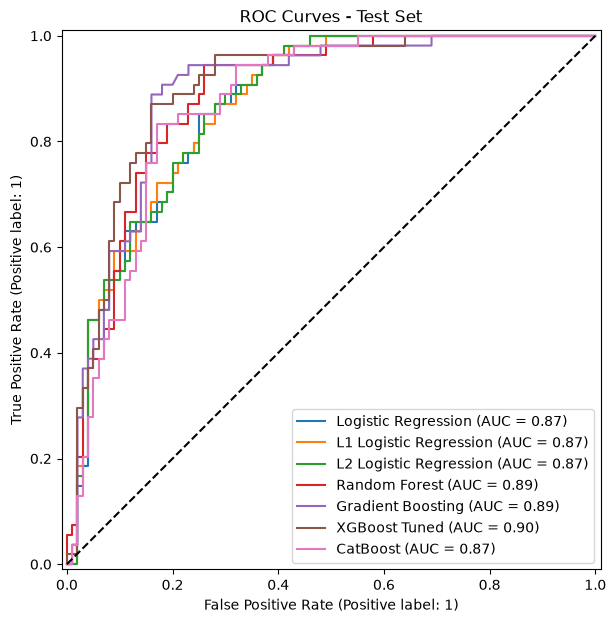

In [35]:
fitted_models = {
    "Logistic Regression": logistic_model,
    "L1 Logistic Regression": l1_grid.best_estimator_,
    "L2 Logistic Regression": l2_grid.best_estimator_,
    "Random Forest": rf_grid.best_estimator_,
    "Gradient Boosting": gb_grid.best_estimator_,
    "XGBoost Tuned": xgb_grid.best_estimator_,
    "CatBoost": cat_pipeline
}

plt.figure(figsize=(9, 7))
ax = plt.gca()
for name, model in fitted_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.title("ROC Curves - Test Set")
plt.show()

## 17. Feature importance

Tree-based models provide a feature-importance estimate. Importance is model-specific and should not be interpreted as causal evidence or as a clinical explanation.

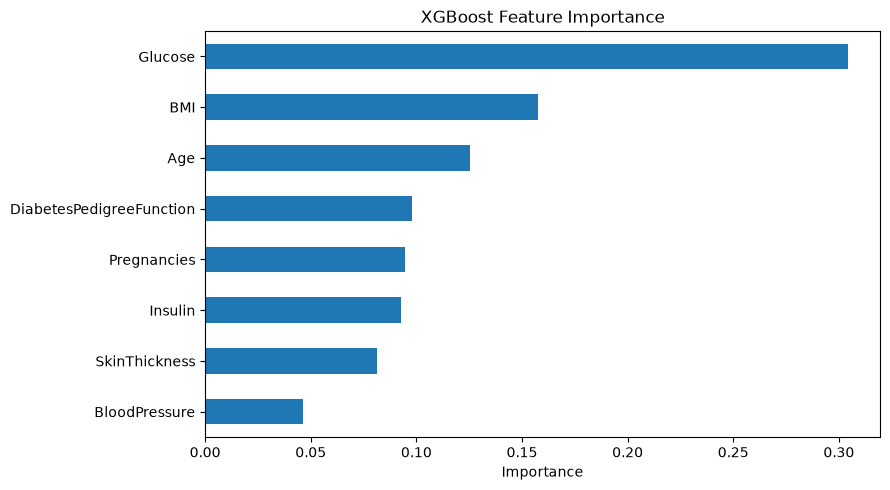

In [36]:
best_tree_model = xgb_grid.best_estimator_.named_steps["classifier"]
importance = pd.Series(
    best_tree_model.feature_importances_, index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(9, 5))
importance.sort_values().plot(kind="barh")
plt.title("XGBoost Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 18. Predict on a new example

This demonstrates how to obtain a predicted class and estimated probability. Values below are illustrative inputs, not a real patient record. Do not use the result for diagnosis or treatment.

In [37]:
sample_patient = pd.DataFrame([{
    "Pregnancies": 2,
    "Glucose": 120,
    "BloodPressure": 70,
    "SkinThickness": 25,
    "Insulin": 80,
    "BMI": 28.5,
    "DiabetesPedigreeFunction": 0.45,
    "Age": 30
}])

chosen_model = xgb_grid.best_estimator_
predicted_class = chosen_model.predict(sample_patient)[0]
predicted_probability = chosen_model.predict_proba(sample_patient)[0, 1]

print("Predicted class:", predicted_class)
print("Estimated probability of class 1:", round(float(predicted_probability), 3))

Predicted class: 0
Estimated probability of class 1: 0.286


## 19. Conclusion

In this project we completed data understanding, cleaning, EDA, preprocessing, train-test splitting, classification model training, evaluation and hyperparameter tuning.

Algorithms covered:
1. Logistic Regression
2. L1-regularized Logistic Regression (Lasso-style)
3. L2-regularized Logistic Regression (Ridge-style)
4. Gaussian Naive Bayes
5. K-Nearest Neighbors (KNN), with GridSearchCV tuning
6. Decision Tree, with GridSearchCV tuning
7. Random Forest Classifier
8. Gradient Boosting Classifier
9. XGBoost Classifier (default)
10. XGBoost Classifier (GridSearchCV tuned)
11. CatBoost Classifier (optional)

**Important:** Do not write a conclusion claiming one model is best until you run the notebook and inspect the test-set results. The best model depends on the evaluation metric and error trade-offs. For a healthcare application, discuss false negatives, false positives, recall, precision, calibration, external validation, population bias and clinical review.

we have to select **RandomForest** because it performance very well 

### Limitations
- Small dataset (768 records) and a narrow population.
- Dataset labels and measurements may contain limitations.
- A random train-test split is not external clinical validation.
- Class probability estimates may need calibration.
- This is an educational demonstration, not a diagnostic product.